In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Importing the ICLR OpenReview Dataset

In [2]:
# Master dataframe made by data/generate.py: every paper (2017-2025) without "Anonymous",
# with its SBERT embedding, last author, and outcome. It lives outside the repo.
iclr2025v2 = pd.read_parquet("../embeddings/master.parquet")
iclr2025v2.head()

,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels
0,2017,B1-Hhnslg,Prototypical Networks for Few-shot Learning,A recent approach to few-shot classification c...,"Jake Snell, Kevin Swersky, Richard Zemel",,Reject,"[6, 4, 5]","[deep learning, transfer learning]",transfer learning
1,2017,B1-q5Pqxl,Machine Comprehension Using Match-LSTM and Ans...,Machine comprehension of text is an important ...,"Shuohang Wang, Jing Jiang",,Accept (Poster),"[6, 6, 7]","[natural language processing, deep learning]",language models
2,2017,B16Jem9xe,Learning in Implicit Generative Models,Generative adversarial networks (GANs) provide...,"Shakir Mohamed, Balaji Lakshminarayanan",,Invite to Workshop Track,"[8, 7, 6]",[unsupervised learning],unlabeled
3,2017,B16dGcqlx,Third Person Imitation Learning,Reinforcement learning (RL) makes it possible ...,"Bradly C Stadie, Pieter Abbeel, Ilya Sutskever",,Accept (Poster),"[6, 5, 6]",[],unlabeled
4,2017,B184E5qee,Improving Neural Language Models with a Contin...,We propose an extension to neural network lang...,"Edouard Grave, Armand Joulin, Nicolas Usunier",,Accept (Poster),"[7, 9, 5]",[natural language processing],language models


# Paper Representation: Loading the SBERT Embeddings

The embeddings come from the master dataframe, so row `i` of the embeddings is row `i` of the dataframe above. We normalise them so that a dot product between two papers is their cosine similarity.

In [ ]:
embedding_av = np.stack(iclr2025v2["embedding"])
print("Embedding shape:", embedding_av.shape)

embedding_av = embedding_av / np.linalg.norm(embedding_av, axis=1, keepdims=True)

Embedding shape: (36070, 768)


# Resubmissions

Note for the group: a paper rejected from ICLR is often resubmitted the next year with an almost identical abstract. Its pivot is then close to 0, because its own earlier version is part of the author's history, and its decision partly depends on the earlier rejection.

We treat two papers as versions of the same paper when they share an author, come from different years, and have a cosine similarity of at least 0.90. Above 0.90 the pairs we inspected were almost all resubmissions (often with the same title); below it they mix renamed resubmissions with follow-up papers, which we want to keep. Rule: if one version was accepted we keep only that one, otherwise we keep only the latest version. The other versions are left out of the analysis and of the authors' histories.

In [4]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# Group paper indices by author
papers_by_author = {}

for idx, row in iclr2025v2.iterrows():
    for author in dict.fromkeys(a.strip() for a in row["authors"].split(",") if a.strip()):
        papers_by_author.setdefault(author, []).append(idx)

# Pairs of near-identical papers that share an author and come from different years
similarity_threshold = 0.90
paper_years = iclr2025v2["year"].to_numpy()
pairs = set()

for author, indices in papers_by_author.items():

    if len(indices) < 2:
        continue

    indices = np.array(indices)
    similarities = embedding_av[indices] @ embedding_av[indices].T
    rows, cols = np.where(np.triu(similarities >= similarity_threshold, k=1))

    for r, c in zip(rows, cols):
        if paper_years[indices[r]] != paper_years[indices[c]]:
            pairs.add((indices[r], indices[c]))

# Link the pairs into chains of versions (A -> B -> C)
pairs = np.array(sorted(pairs))
graph = coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(len(iclr2025v2), len(iclr2025v2)))
_, chain_id = connected_components(graph, directed=False)

resubmissions = iclr2025v2.assign(chain=chain_id, accepted=iclr2025v2["decision"].str.startswith("Accept"))
resubmissions = resubmissions[resubmissions.groupby("chain")["id"].transform("size") > 1]

# Keep the accepted version if there is one, otherwise the latest version
kept = resubmissions.sort_values(["accepted", "year"]).groupby("chain").tail(1).index
resubmission_drop = set(resubmissions.index) - set(kept)

print(f"Chains of resubmitted papers: {resubmissions['chain'].nunique()}")
print(f"Chains with an accepted version: {resubmissions.groupby('chain')['accepted'].any().sum()}")
print(f"Papers left out: {len(resubmission_drop)} of {len(iclr2025v2)}")

Chains of resubmitted papers: 502
Chains with an accepted version: 128
Papers left out: 521 of 36070


In [23]:
# A few chains, with the version we keep
resubmissions["kept"] = resubmissions.index.isin(kept)
sample_chains = resubmissions["chain"].drop_duplicates().sample(5, random_state=42)

resubmissions[resubmissions["chain"].isin(sample_chains)].sort_values(["chain", "year"])[["chain", "year", "decision", "kept", "title"]]

,chain,year,decision,kept,title
5769,5733,2021,Reject,False,NAS-Bench-301 and the Case for Surrogate Bench...
9977,5733,2022,Accept (Poster),True,Surrogate NAS Benchmarks: Going Beyond the Lim...
7621,7565,2021,Reject,False,DeeperGCN: Training Deeper GCNs with Generaliz...
11533,7565,2022,Withdrawn,True,DeeperGCN: All You Need to Train Deeper GCNs
9795,9713,2022,Withdrawn,False,Theoretical understanding of adversarial reinf...
15299,9713,2023,Reject,True,Probe Into Multi-agent Adversarial Reinforceme...
14378,14221,2023,Reject,False,MA2QL: A Minimalist Approach to Fully Decentra...
16476,14221,2023,Reject,False,Best Possible Q-Learning
20215,14221,2024,Reject,False,Best Possible Q-Learning
30314,14221,2025,Reject,True,Best Possible Q-Learning


# Pivot Index

We define the pivot index of a paper $j$ by author $a$ published in year $t$ as

$$\Phi_{aj} = 1 - \cos\left(e_j, \bar e_{H(a,t)}\right),$$

where $\bar e_{H(a,t)}$ is the mean embedding of all of the author's papers from years before $t$. The idea comes from Hill et al. (2025), but we measure prior work through abstract embeddings. A pivot close to 0 means the paper stays close to the author's prior work. Papers from the same year are not part of the history, and the pivot is undefined for an author's first year.

We also compute two alternatives that use the author's history differently:
- **Nearest prior paper:** $\Phi^{nn}_{aj} = 1 - \max_{i \in H(a,t)} \cos(e_j, e_i)$, how far the paper is from the most similar paper the author has written before.
- **Mean of the $k$ closest prior papers:** the same as $\Phi_{aj}$, but the mean embedding only uses the $k = 3$ earlier papers most similar to $e_j$. Since $k$ is below our threshold of 5 prior papers, every PI pivot of this kind is built from exactly 3 papers.

In [24]:
# Making the paper-author dataframe, one row per author of each paper
records = []

for idx, row in iclr2025v2.iterrows():

    # leave out the other versions of resubmitted papers
    if idx in resubmission_drop:
        continue

    # splitting list of authors
    paper_authors = list(dict.fromkeys(
        a.strip()
        for a in row["authors"].split(",")
        if a.strip()
    ))

    for position, author in enumerate(paper_authors):
        records.append({
            "paper_idx": idx,
            "paper_id": row["id"],
            "year": row["year"],
            "author": author,
            "is_last_author": position == len(paper_authors) - 1,
            "decision": row["decision"],
        })

author_papers = pd.DataFrame(records)
author_papers.head()

,paper_idx,paper_id,year,author,is_last_author,decision
0,0,B1-Hhnslg,2017,Jake Snell,False,Reject
1,0,B1-Hhnslg,2017,Kevin Swersky,False,Reject
2,0,B1-Hhnslg,2017,Richard Zemel,True,Reject
3,1,B1-q5Pqxl,2017,Shuohang Wang,False,Accept (Poster)
4,1,B1-q5Pqxl,2017,Jing Jiang,True,Accept (Poster)


In [25]:
# For each paper of an author, compare it to the mean embedding of the author's earlier papers,
# to the nearest earlier paper, and to the mean embedding of the k closest earlier papers
k = 3
pivot_records = []

for author, group in author_papers.groupby("author"):

    # from the author-defined group:
    paper_indices = group["paper_idx"].to_numpy() # list of all paper indices
    years = group["year"].to_numpy() # list of all years

    for paper_idx, year in zip(paper_indices, years):

        prior_indices = paper_indices[years < year] # prior history

        if len(prior_indices) == 0:
            pivot = np.nan
            pivot_nn = np.nan
            pivot_k = np.nan
            nearest_prior_idx = -1
        else:

            # OG prior history vector
            prior_mean = embedding_av[prior_indices].mean(axis=0) # prior history vector
            prior_mean = prior_mean / np.linalg.norm(prior_mean) # normalized
            pivot = 1 - embedding_av[paper_idx] @ prior_mean

            # similarity of the present paper to EACH of the author's earlier papers
            similarities = embedding_av[prior_indices] @ embedding_av[paper_idx]

            # nearest prior paper
            pivot_nn = 1 - similarities.max()
            nearest_prior_idx = prior_indices[similarities.argmax()]

            # mean embedding of the k = 3 closest prior papers
            closest_indices = prior_indices[np.argsort(similarities)[-k:]]
            closest_mean = embedding_av[closest_indices].mean(axis=0)
            closest_mean = closest_mean / np.linalg.norm(closest_mean)


            
            pivot_k = 1 - embedding_av[paper_idx] @ closest_mean

        pivot_records.append({
            "paper_idx": paper_idx,
            "author": author,
            "n_prior": len(prior_indices),
            "pivot": pivot,
            "pivot_nn": pivot_nn,
            "pivot_k": pivot_k,
            "nearest_prior_idx": nearest_prior_idx,
        })

author_papers = author_papers.merge(pd.DataFrame(pivot_records), on=["paper_idx", "author"])


In [26]:
author_papers.head(20)

,paper_idx,paper_id,year,author,is_last_author,decision,n_prior,pivot,pivot_nn,pivot_k,nearest_prior_idx
0,0,B1-Hhnslg,2017,Jake Snell,False,Reject,0,NaN,NaN,NaN,-1
1,0,B1-Hhnslg,2017,Kevin Swersky,False,Reject,0,NaN,NaN,NaN,-1
2,0,B1-Hhnslg,2017,Richard Zemel,True,Reject,0,NaN,NaN,NaN,-1
3,1,B1-q5Pqxl,2017,Shuohang Wang,False,Accept (Poster),0,NaN,NaN,NaN,-1
4,1,B1-q5Pqxl,2017,Jing Jiang,True,Accept (Poster),0,NaN,NaN,NaN,-1
5,2,B16Jem9xe,2017,Shakir Mohamed,False,Invite to Workshop Track,0,NaN,NaN,NaN,-1
6,2,B16Jem9xe,2017,Balaji Lakshminarayanan,True,Invite to Workshop Track,0,NaN,NaN,NaN,-1
7,3,B16dGcqlx,2017,Bradly C Stadie,False,Accept (Poster),0,NaN,NaN,NaN,-1
8,3,B16dGcqlx,2017,Pieter Abbeel,False,Accept (Poster),0,NaN,NaN,NaN,-1
9,3,B16dGcqlx,2017,Ilya Sutskever,True,Accept (Poster),0,NaN,NaN,NaN,-1


For each paper we keep the pivot of the last listed author (the PI), as in our initial analysis. We only keep PIs with at least 5 papers in earlier years so that the mean of their prior work is meaningful.

In [27]:
threshold = 5

pi_pivot = author_papers[
    author_papers["is_last_author"] & (author_papers["n_prior"] >= threshold)
].copy()

pi_pivot = pi_pivot.merge(iclr2025v2[["id", "title"]], left_on="paper_id", right_on="id").drop(columns="id")

print(f"Papers with a PI pivot: {len(pi_pivot)} of {len(iclr2025v2)}")
pi_pivot["pivot"].describe()

Papers with a PI pivot: 13126 of 36070


count    13126.000000
mean         0.408679
std          0.115298
min          0.098284
25%          0.325910
50%          0.400723
75%          0.482771
max          0.925316
Name: pivot, dtype: float64

# Initial Analysis

Exploratory. Observe that the mean pivot index value is 0.4: it's common for researchers to include some topic pivoting in their publishing. Distribution is right skewed (makes sense, researchers tend to specialize). The proportion of researchers pivoting very high (0.6 <=) is limited.

If we look a pivot index by year, we must be cautious. Initial years do not have prior history (or it might not be representative of the whole history). The standard errors decrease through the years: also makes sense, there are more papers to represent the prior history, pivoting tends to concentrate around the mean.

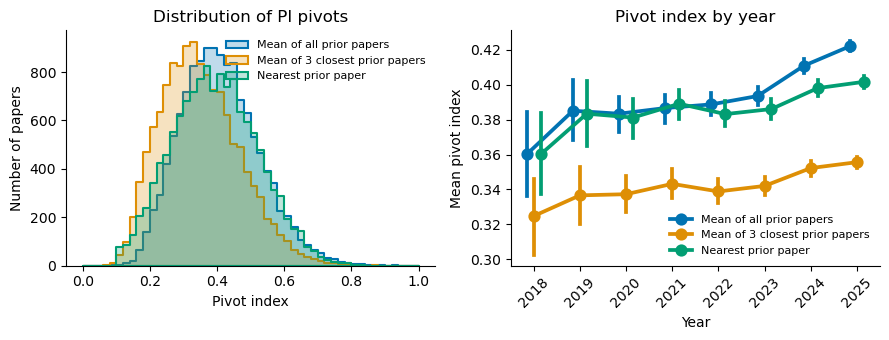

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

methods = {
    "pivot": "Mean of all prior papers",
    "pivot_k": "Mean of 3 closest prior papers",
    "pivot_nn": "Nearest prior paper",
}
colors = sns.color_palette("colorblind")[:3]
bins = np.linspace(0, 1, 51)  # same bins for every method so the bars line up

# simple distrbution across all papers
for (column, label), color in zip(methods.items(), colors):
    sns.histplot(pi_pivot[column], bins=bins, ax=axs[0], color=color, alpha=0.25, element="step", linewidth=1.5, label=label)
axs[0].set(xlabel="Pivot index", ylabel="Number of papers", title="Distribution of PI pivots")
axs[0].legend(fontsize=8, frameon=False)

# through years
pi_long = pi_pivot.melt(id_vars="year", value_vars=list(methods), var_name="method", value_name="value")
pi_long["method"] = pi_long["method"].map(methods)

sns.pointplot(
    data=pi_long, x="year", y="value", hue="method", hue_order=list(methods.values()),
    palette=colors, dodge=0.3, ax=axs[1]
)
axs[1].set(xlabel="Year", ylabel="Mean pivot index", title="Pivot index by year")
axs[1].tick_params(axis="x", rotation=45)
axs[1].legend(fontsize=8, frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

To check that the index behaves as expected, we look at the papers of one prolific PI with the lowest and highest pivots.

### Example from Levine

Notes for the group:
- I realize PIs tend to appear more than once per year (because they lead many projects), like in year 2021. How do we aggregate for yearly pivot index if one of the papers is close to past topics and one is fundamentally different?
- Resubmissions. Some papers get resubmitted in the future when rejected in earlier years, in which case there is already a paper that matches perfectly the embedding. A rule that I came up with: if accepted, only put it in the year that it got, if not accepted, drop duplicates and put first year. There are 33 of this. We can also filter out papers that fall under 0.05.

In [29]:
author = "Sergey Levine"
example = pi_pivot[pi_pivot["author"] == author].sort_values("pivot")

pd.concat([example.head(3), example.tail(3)])[["year", "n_prior", "pivot", "title"]]

,year,n_prior,pivot,title
84,2019,19,0.149379,Unsupervised Exploration with Deep Model-Based...
1038,2021,71,0.160419,Parrot: Data-Driven Behavioral Priors for Rein...
64,2018,7,0.160844,Divide-and-Conquer Reinforcement Learning
1096,2021,71,0.575645,Design-Bench: Benchmarks for Data-Driven Offli...
5529,2024,141,0.658804,Latent Conservative Objective Models for Offli...
1669,2022,101,0.714300,Data-Driven Offline Optimization for Architect...


Super noisy metric as expected. Especially with prolific individuals.

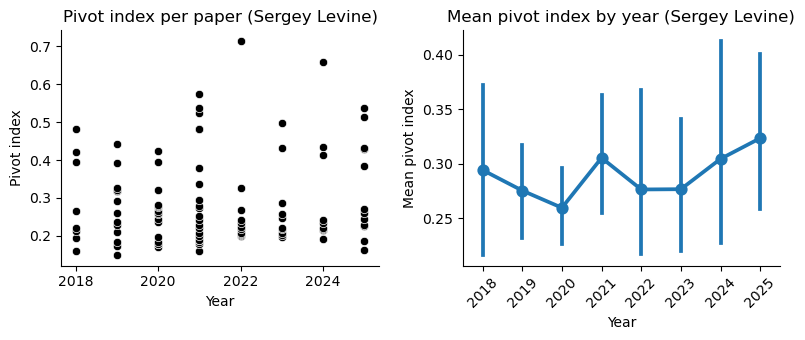

In [30]:
# Sergey Levine's pivot index across years (papers where he is the last author)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.5))

# Pivot index of each paper
sns.scatterplot(data=example, x="year", y="pivot", ax=axs[0], color="black")
axs[0].set(xlabel="Year", ylabel="Pivot index", title="Pivot index per paper (Sergey Levine)")

# Mean pivot index per year, with 95% confidence intervals
sns.pointplot(data=example, x="year", y="pivot", ax=axs[1], estimator="mean")
axs[1].set(xlabel="Year", ylabel="Mean pivot index", title="Mean pivot index by year (Sergey Levine)")
axs[1].tick_params(axis="x", rotation=45)

sns.despine()
plt.tight_layout()
plt.show()

### Alternative histories for Levine

For the nearest prior paper, we also show which earlier paper it is, so we can check that the match makes sense.

In [31]:
# Nearest prior paper: lowest and highest pivots, with the earlier paper each one is closest to
example_nn = example.sort_values("pivot_nn").copy()
example_nn["nearest_prior_title"] = iclr2025v2.loc[example_nn["nearest_prior_idx"], "title"].to_numpy()

pd.concat([example_nn.head(3), example_nn.tail(3)])[["year", "n_prior", "pivot_nn", "title", "nearest_prior_title"]]

,year,n_prior,pivot_nn,title,nearest_prior_title
501,2020,43,0.111741,"Deep Imitative Models for Flexible Inference, ...","Deep Imitative Models for Flexible Inference, ..."
1259,2021,71,0.112011,Learning to Reach Goals via Iterated Supervise...,Learning to Reach Goals Without Reinforcement ...
2322,2022,101,0.126549,Offline Meta-Reinforcement Learning with Onlin...,Offline Meta-Reinforcement Learning with Advan...
893,2021,71,0.502024,X2T: Training an X-to-Text Typing Interface wi...,Guiding Policies with Language via Meta-Learning
65,2018,7,0.505684,Stochastic Variational Video Prediction,Learning Visual Servoing with Deep Features an...
1669,2022,101,0.539831,Data-Driven Offline Optimization for Architect...,Design-Bench: Benchmarks for Data-Driven Offli...


In [32]:
# Mean of the k closest prior papers: lowest and highest pivots
example_k = example.sort_values("pivot_k")

pd.concat([example_k.head(3), example_k.tail(3)])[["year", "n_prior", "pivot_k", "title"]]

,year,n_prior,pivot_k,title
2322,2022,101,0.074531,Offline Meta-Reinforcement Learning with Onlin...
316,2020,43,0.103579,Learning to Reach Goals Without Reinforcement ...
3686,2023,123,0.105828,Fully Online Meta Learning
893,2021,71,0.439092,X2T: Training an X-to-Text Typing Interface wi...
65,2018,7,0.478883,Stochastic Variational Video Prediction
1669,2022,101,0.540696,Data-Driven Offline Optimization for Architect...


In [33]:
# How the three measures rank papers, for Levine and for all PI papers (Spearman correlation)
print("Sergey Levine")
print(example[["pivot", "pivot_k", "pivot_nn"]].corr(method="spearman").round(2))
print()

print("All PIs")
pi_pivot[["pivot", "pivot_k", "pivot_nn"]].corr(method="spearman").round(2)

Sergey Levine
          pivot  pivot_k  pivot_nn
pivot      1.00     0.71      0.65
pivot_k    0.71     1.00      0.92
pivot_nn   0.65     0.92      1.00

All PIs


,pivot,pivot_k,pivot_nn
pivot,1.00,0.85,0.74
pivot_k,0.85,1.00,0.92
pivot_nn,0.74,0.92,1.00


Since withdrawn and desk-rejected papers never received a final decision, we leave them out when looking at acceptance.

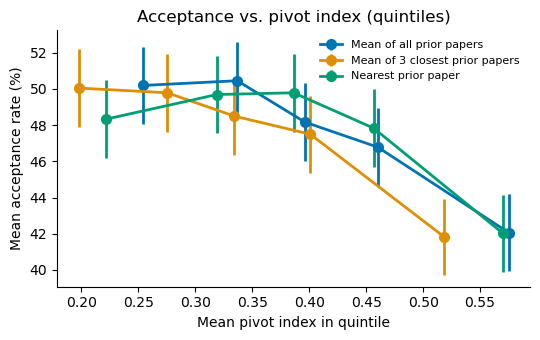

,method,pivot_bin,pivot_range,acceptance,n_papers
5,Mean of all prior papers,Q1,0.10 - 0.30,50.2,2100
6,Mean of all prior papers,Q2,0.30 - 0.37,50.5,2099
7,Mean of all prior papers,Q3,0.37 - 0.43,48.2,2099
8,Mean of all prior papers,Q4,0.43 - 0.50,46.8,2099
9,Mean of all prior papers,Q5,0.50 - 0.86,42.1,2099
0,Mean of 3 closest prior papers,Q1,0.07 - 0.24,50.0,2100
1,Mean of 3 closest prior papers,Q2,0.24 - 0.31,49.8,2099
2,Mean of 3 closest prior papers,Q3,0.31 - 0.36,48.5,2099
3,Mean of 3 closest prior papers,Q4,0.36 - 0.44,47.5,2099
4,Mean of 3 closest prior papers,Q5,0.44 - 0.81,41.8,2099


In [34]:
# filtering out 
decided = pi_pivot[~pi_pivot["decision"].isin(["Withdrawn", "Desk rejected"])].copy()
decided["accepted"] = decided["decision"].str.startswith("Accept")

# Divide into quintiles of each pivot index (each method gets its own quintiles)
quintile_labels = ["Q1", "Q2", "Q3", "Q4", "Q5"]
decided_long = []

for column, label in methods.items():
    rows = decided[["paper_id", "accepted"]].copy()
    rows["pivot_value"] = decided[column]
    rows["pivot_bin"] = pd.qcut(decided[column], q=5, labels=quintile_labels)
    rows["method"] = label
    decided_long.append(rows)

decided_long = pd.concat(decided_long, ignore_index=True)
decided_long["acceptance"] = decided_long["accepted"] * 100

# Mean pivot value and acceptance rate in each quintile, with a 95% confidence interval
binned = decided_long.groupby(["method", "pivot_bin"], observed=True).agg(
    pivot_mean=("pivot_value", "mean"),
    pivot_min=("pivot_value", "min"),
    pivot_max=("pivot_value", "max"),
    acceptance=("acceptance", "mean"),
    n_papers=("paper_id", "count"),
).reset_index()
binned["ci"] = 1.96 * np.sqrt(binned["acceptance"] * (100 - binned["acceptance"]) / binned["n_papers"])

fig, ax = plt.subplots(figsize=(5.5, 3.5))

# each point is one quintile, placed at its mean pivot value
for label, color in zip(methods.values(), colors):
    group = binned[binned["method"] == label]
    ax.errorbar(group["pivot_mean"], group["acceptance"], yerr=group["ci"],
                color=color, marker="o", markersize=7, linewidth=2, label=label)

ax.set(
    xlabel="Mean pivot index in quintile",
    ylabel="Mean acceptance rate (%)",
    title="Acceptance vs. pivot index (quintiles)"
)
ax.legend(fontsize=8, frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

# pivot range of each quintile
binned["pivot_range"] = binned["pivot_min"].map("{:.2f}".format) + " - " + binned["pivot_max"].map("{:.2f}".format)
binned["method"] = pd.Categorical(binned["method"], categories=list(methods.values()))
binned.sort_values(["method", "pivot_bin"])[["method", "pivot_bin", "pivot_range", "acceptance", "n_papers"]].round(1)

# Sanity Checks

The embeddings do not store paper ids, so we check that row `i` of the embeddings is row `i` of the dataframe: papers with the same abstract must have the same embedding.

In [35]:
assert len(embedding_av) == len(iclr2025v2)

duplicates = iclr2025v2[iclr2025v2["abstract"].duplicated(keep=False)].groupby("abstract").groups

for indices in duplicates.values():
    assert np.allclose(embedding_av[indices[0]], embedding_av[indices[1]])

print(f"Embeddings line up with the dataframe ({len(duplicates)} duplicated abstracts checked)")

Embeddings line up with the dataframe (33 duplicated abstracts checked)


The threshold of 5 prior papers is a choice. Below we recompute the acceptance rate by pivot quintile for other thresholds, and the gap in acceptance between the lowest (Q1) and highest (Q5) pivot quintiles.

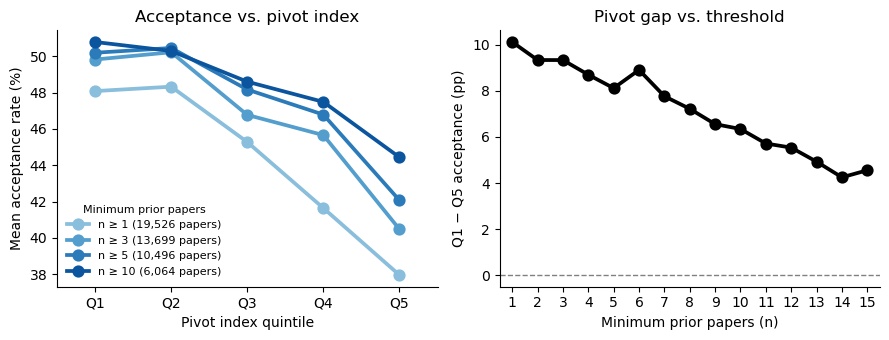

,threshold,gap,n_papers
0,1,10.128533,19526
1,2,9.344924,16102
2,3,9.343066,13699
3,4,8.706572,11945
4,5,8.122825,10496
5,6,8.915145,9310
6,7,7.771084,8300
7,8,7.224080,7473
8,9,6.558585,6782
9,10,6.347898,6064


In [36]:
quintiles = ["Q1", "Q2", "Q3", "Q4", "Q5"]
sensitivity = []
gaps = []

for n in range(1, 16):

    subset = author_papers[
        author_papers["is_last_author"]
        & (author_papers["n_prior"] >= n)
        & ~author_papers["decision"].isin(["Withdrawn", "Desk rejected"])
    ].copy()
    subset["accepted"] = subset["decision"].str.startswith("Accept")
    subset["pivot_bin"] = pd.qcut(subset["pivot"], q=5, labels=quintiles)

    rates = subset.groupby("pivot_bin", observed=True)["accepted"].mean() * 100

    gaps.append({"threshold": n, "gap": rates["Q1"] - rates["Q5"], "n_papers": len(subset)})

    if n in [1, 3, 5, 10]:
        for pivot_bin, rate in rates.items():
            sensitivity.append({
                "threshold": f"n ≥ {n} ({len(subset):,} papers)",
                "pivot_bin": pivot_bin,
                "mean_acceptance": rate,
            })

sensitivity = pd.DataFrame(sensitivity)
gaps = pd.DataFrame(gaps)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

sns.pointplot(
    data=sensitivity,
    x="pivot_bin",
    y="mean_acceptance",
    hue="threshold",
    palette=sns.color_palette("Blues", 6)[2:],
    ax=axs[0]
)
axs[0].set(
    xlabel="Pivot index quintile",
    ylabel="Mean acceptance rate (%)",
    title="Acceptance vs. pivot index"
)
axs[0].legend(title="Minimum prior papers", fontsize=8, title_fontsize=8, frameon=False)

sns.pointplot(data=gaps, x="threshold", y="gap", ax=axs[1], color="black")
axs[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axs[1].set(
    xlabel="Minimum prior papers (n)",
    ylabel="Q1 − Q5 acceptance (pp)",
    title="Pivot gap vs. threshold"
)

sns.despine()
plt.tight_layout()
plt.show()

gaps

# Caveats
- **Resubmissions are detected with a cosine threshold of 0.90.** Some resubmissions with edited abstracts fall below it and remain.
- **History length matters.** The acceptance gap between low- and high-pivot papers shrinks for PIs with long histories; we cannot yet tell experience apart from a more stable average.
- **Topic drift.** Pivots rise after 2023 (LLM era), and we do not control for topic.